<font face="Times New Roman" size=5>
<div dir=rtl align="center">
<font face="Times New Roman" size=5>
In The Name of God
</font>
<br>
<img src="https://logoyar.com/content/wp-content/uploads/2021/04/sharif-university-logo.png" alt="University Logo" width="150" height="150">
<br>
<font face="Times New Roman" size=4 align=center>
Sharif University of Technology - Department of Electrical Engineering
</font>
<br>
<font color="#008080" size=6>
Deep Generative Models
</font>
<hr/>
<font color="#800080" size=5>
Assignment 2 : Deep Autoregressive Models
<br>
</font>
<font size=5>
Instructor: Dr. S. Amini
<br>
</font>
<font size=4>
Fall 2025
<br>
</font>
<font face="Times New Roman" size=4>
</font>
<hr>
<font color='red'  size=4>
<br>
</font>
<font face="Times New Roman" size=4 align=center>
Feel free to ask your questions in Telegram : @ZahraSorkhei, @Ali99os
</font>
<br>
<hr>
</div></font>

**You should only change the blank sections, marked with TODO**

Pay attention to docstrings, as they may drastically help with your implementation.

You are advised to read all related papers and material, to help you better understand the design of each model.

# Question 1: Probabilistic Graph Forecasting with Autoregressive Decoders

This note gives a concise introduction to a temporal latent-variable model for **graph sequences** $\{G_t\}_{t=1}^T$ with $G_t=(X_t,A_t)$. It states the model, the training objective (ELBO) in a time-factorized form, the concrete likelihoods used for node features and edges, the effect of a deterministic decoder, and how to generate future graphs.



## Problem setup

We observe a sequence of graph snapshots

$$
G_t = (X_t, A_t), \quad t=1,\dots,T,
$$

where $X_t \in \mathbb{R}^{n \times d}$ stacks node feature vectors $x_t^v$ and $A_t \in \{0,1\}^{n \times n}$ is an undirected adjacency matrix (no self-loops). To capture temporal structure we introduce a latent trajectory

$$
Z_{1:T} = (Z_1, \dots, Z_T), \quad Z_t \in \mathbb{R}^m,
$$

where $Z_t$ is a global latent representation of the whole graph at time $t$.


## Generative (autoregressive latent) model

An autoregressive factorization is used:

$$
p_\theta(X_{1:T}, A_{1:T}, Z_{1:T})
= p(Z_1) \prod_{t=1}^{T-1} p_\theta(Z_{t+1}\mid Z_t)\; p_\theta(X_{t+1}, A_{t+1}\mid Z_t)
$$

Intuition: the latent $Z_t$ summarizes the state at $t$; a transition model $p_\theta(Z_{t+1}\mid Z_t)$ evolves it; conditioned on the current latent we predict the *next* snapshot $(X_{t+1}, A_{t+1})$.

We approximate the true posterior with an amortized encoder (e.g. a GNN+RNN):

$$
q_\phi(Z_t \mid X_{1:t}, A_{1:t}) \quad \text{(often factorized across $t$ for amortization).}
$$


## Variational lower bound (ELBO) — time decomposition

Using the variational approximation

$$
q_\phi(Z_{1:T}\mid X_{1:T},A_{1:T}) = \prod_{t=1}^T q_\phi(Z_t \mid X_{1:t},A_{1:t}),
$$

the marginal log-likelihood admits the ELBO:

$$
\log p_\theta(X_{1:T}, A_{1:T}) \ge
\mathbb{E}_{q_\phi} \Big[ \sum_{t=1}^{T-1} \log p_\theta(X_{t+1}, A_{t+1} \mid Z_t) \Big]
- \mathrm{KL}\big(q_\phi(Z_1 \mid X_1, A_1) \,\|\, p(Z_1)\big)
- \sum_{t=1}^{T-1} \mathbb{E}_{q_\phi} \Big[ \mathrm{KL}\big(q_\phi(Z_{t+1}\mid X_{1:t+1}, A_{1:t+1}) \,\|\, p_\theta(Z_{t+1}\mid Z_t)\big) \Big].
$$

Thus the objective is a sum over time: per-step reconstruction terms plus per-step KL penalties that align the encoder's posterior with the learned transition prior.



## Explicit reconstruction likelihoods

If the decoder factorizes into Gaussian node-features and Bernoulli edges:

- **Node features (per node $v$)**

$$
p_\theta(x_{t+1}^v \mid Z_t) = \mathcal{N}(x_{t+1}^v \mid \mu_\theta^v(Z_t), \Sigma_\theta^v(Z_t)),
$$

hence the feature log-likelihood (for all nodes) is

$$
\log p_\theta(X_{t+1} \mid Z_t)
= -\frac{1}{2} \sum_{v=1}^n \Big[ (x_{t+1}^v - \mu_\theta^v)^\top (\Sigma_\theta^v)^{-1} (x_{t+1}^v - \mu_\theta^v) + \log \det(2 \pi \Sigma_\theta^v) \Big].
$$

(In practice $\Sigma^v$ is taken diagonal or shared for numerical stability.)

- **Edges (for unordered pairs $u<v$)**

$$
p_\theta(A_{t+1} \mid Z_t) = \prod_{u<v} \mathrm{Bernoulli}\big(A_{t+1}^{uv} \mid \pi_\theta^{uv}(Z_t)\big),
$$

so

$$
\log p_\theta(A_{t+1} \mid Z_t) = \sum_{u<v} \Big[ A_{uv} \log \pi_{uv} + (1-A_{uv}) \log (1-\pi_{uv}) \Big].
$$

Combine them:

$$
\log p_\theta(X_{t+1}, A_{t+1} \mid Z_t) = \log p_\theta(X_{t+1} \mid Z_t) + \log p_\theta(A_{t+1} \mid Z_t).
$$


## Deterministic decoder

If the decoder is deterministic (e.g. $X_{t+1}=f_\theta(Z_t)$, $A_{t+1}=g_\theta(Z_t)$ or equivalently Gaussian with vanishing variance), then:

- The likelihood becomes a Dirac (or degenerate Gaussian); log-likelihood is $-\infty$ off the model manifold — numerically unstable.
- Deterministic decoders cannot model multimodality: a single $Z_t$ maps to a single snapshot, so they fail when the conditional distribution is multi-valued.
- Training tends to overfit (model memorizes) or produce poor uncertainty calibration. Probabilistic decoders (non-zero variance, Bernoulli edges) are preferred for stable likelihood-based training and to capture uncertainty/diversity.


## Generating future graphs

Given observed history $X_{1:T}, A_{1:T}$:

1. Infer the posterior at final time: $q_\phi(Z_T \mid X_{1:T}, A_{1:T})$ and sample $z_T \sim q_\phi$ (or use the posterior mean).
2. For $h=1$ to $H$:
   - Sample latent: $z_{T+h} \sim p_\theta(Z_{T+h} \mid z_{T+h-1})$.
   - Sample (or take mean of) snapshot: $(\tilde X_{T+h}, \tilde A_{T+h}) \sim p_\theta(\cdot \mid z_{T+h-1})$ (or use the decoder mean).





In [67]:
import math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import networkx as nx
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

## 1) Synthetic dynamic graph dataset
**Goal:**  
Create dynamic graphs using SBM with Gaussian node features.

**Hints:**  
- `generate_sbm`: adjacency with `p_in` (intra) and `p_out` (inter) edges.  
- `generate_features`: node features from `N(μ_k, Σ_k)` per community.  
- `generate_sequence`: simulate T timesteps with drift and edge flips.  
- `_getitem_` / `_len_`: return sequences.  
- `collate_fn`: batch multiple sequences.

**Output:**  
- `X_seq`: `[T, n_nodes, feat_dim]`  
- `A_seq`: `[T, n_nodes, n_nodes]`

In [66]:
class SyntheticGraphDataset(Dataset):
    """
    Generate synthetic evolving graphs.
    Each dataset item is a temporal sequence (length T) of graphs with:
      - X_seq: [T, n_nodes, feat_dim] node features
      - A_seq: [T, n_nodes, n_nodes] adjacency matrices

    We also store per-sequence community assignments for visualization.
    """

    def __init__(self, n_nodes=30, feat_dim=4, T=40, n_seq=200, p_flip=0.03,
                 n_communities: int = 3,
                 p_in: float = 0.4,
                 p_out: float = 0.05,
                 feature_drift_std: float = 0.05):
        """
        Args:
            n_nodes:          Number of nodes per graph.
            feat_dim:         Dimensionality of node features.
            T:                Length of each temporal sequence.
            n_seq:            Number of sequences to generate.
            p_flip:           Edge flip probability between timesteps.
            n_communities:    Number of SBM communities.
            p_in:             Intra-community edge probability.
            p_out:            Inter-community edge probability.
            feature_drift_std:Std of Gaussian noise in feature random walk.
        """
        super().__init__()

        # Store configuration as attributes so generate_sequence can use them.
        self.n_nodes = n_nodes
        self.feat_dim = feat_dim
        self.T = T
        self.n_seq = n_seq
        self.p_flip = p_flip
        self.n_communities = n_communities
        self.p_in = p_in
        self.p_out = p_out
        self.feature_drift_std = feature_drift_std

        # Containers for all pre-generated sequences.
        self.X_sequences = []
        self.A_sequences = []
        self.communities_list = []

        # Pre-generate n_seq sequences and their community labels.
        for _ in range(self.n_seq):
            X_seq, A_seq, communities = self.generate_sequence()
            self.X_sequences.append(X_seq)          # [T, n_nodes, feat_dim]
            self.A_sequences.append(A_seq)          # [T, n_nodes, n_nodes]
            self.communities_list.append(communities)  # [n_nodes]

    def generate_sequence(self):
        """
        Generate a single sequence:
          - Sample communities for each node.
          - Sample initial features from community Gaussians.
          - Sample initial adjacency via SBM.
          - Evolve features via random walk and edges via flips.

        Returns:
            X_seq:      [T, n_nodes, feat_dim]
            A_seq:      [T, n_nodes, n_nodes]
            communities:[n_nodes] community indices for nodes.
        """
        # 1) Assign each node to a community (random uniform assignment).
        communities = torch.randint(
            low=0,
            high=self.n_communities,
            size=(self.n_nodes,),
        )

        # 2) Community-specific feature means.
        community_means = torch.randn(self.n_communities, self.feat_dim)

        # 3) Initialize features at t=0 from the community Gaussians.
        X0 = torch.zeros(self.n_nodes, self.feat_dim)
        for v in range(self.n_nodes):
            community_idx = communities[v]
            X0[v] = community_means[community_idx] + torch.randn(self.feat_dim)

        # 4) Initialize adjacency at t=0 using SBM (p_in / p_out).
        A0 = torch.zeros(self.n_nodes, self.n_nodes, dtype=torch.float32)
        for u in range(self.n_nodes):
            for v in range(u + 1, self.n_nodes):
                if communities[u] == communities[v]:
                    prob = self.p_in
                else:
                    prob = self.p_out
                edge = torch.bernoulli(torch.tensor(prob))
                A0[u, v] = edge
                A0[v, u] = edge

        # Allocate sequence tensors.
        X_seq = torch.zeros(self.T, self.n_nodes, self.feat_dim, dtype=torch.float32)
        A_seq = torch.zeros(self.T, self.n_nodes, self.n_nodes, dtype=torch.float32)

        X_seq[0] = X0
        A_seq[0] = A0

        # 5) Evolve over time: random walk for features, edge flips for adjacency.
        for t in range(1, self.T):
            # Feature random walk.
            noise = torch.randn(self.n_nodes, self.feat_dim) * self.feature_drift_std
            X_seq[t] = X_seq[t - 1] + noise

            # Edge flips.
            A_prev = A_seq[t - 1]
            A_t = A_prev.clone()
            for u in range(self.n_nodes):
                for v in range(u + 1, self.n_nodes):
                    if random.random() < self.p_flip:
                        new_val = 1.0 - A_prev[u, v]
                        A_t[u, v] = new_val
                        A_t[v, u] = new_val

            A_t.fill_diagonal_(0.0)
            A_seq[t] = A_t

        return X_seq, A_seq, communities

    def _len_(self):
        """
        Non-standard len, used by the provided template.
        """
        return self.n_seq

    def _getitem_(self, idx):
        """
        Non-standard getitem, used by the provided template.
        """
        X_seq = self.X_sequences[idx]
        A_seq = self.A_sequences[idx]
        return X_seq, A_seq

    def __len__(self):
        return self._len_()

    def __getitem__(self, idx):
        return self._getitem_(idx)


def collate_fn(batch):
    """
    Collate function for DataLoader.

    Args:
        batch: list of (X_seq, A_seq), each:
               X_seq: [T, n_nodes, feat_dim]
               A_seq: [T, n_nodes, n_nodes]

    Returns:
        X_batch: [B, T, n_nodes, feat_dim]
        A_batch: [B, T, n_nodes, n_nodes]
    """
    X_list, A_list = zip(*batch)
    X_batch = torch.stack(X_list, dim=0)
    A_batch = torch.stack(A_list, dim=0)
    return X_batch, A_batch


## 2) Encoder, Prior, Decoder

### SimpleGraphEncoder
Aggregates node features and degree statistics.  
Computes graph-level latent embeddings `mu` and `logvar` for VAE.  
No external graph libraries required; uses only PyTorch.

### TransitionPrior
Models the latent temporal evolution `p(Z_{t+1} | Z_t)` as a Gaussian.  
Produces mean and variance for autoregressive sampling in VAE.

### Decoder
Reconstructs node features and adjacency matrices from latent `Z_t`.  
Uses node embeddings combined with latent vectors for feature decoding.  
Produces edge logits for Bernoulli reconstruction of adjacency.  
Supports probabilistic reconstruction via Gaussian features + Bernoulli edges.

In [65]:
class SimpleGraphEncoder(nn.Module):
    """
    Simple encoder that aggregates node features and graph degree stats.
    No torch_geometric needed.
    """
    def __init__(self, in_dim: int, latent_dim: int, hidden_dim: int = 64):
        """
        Args:
            in_dim:     Node feature dimension F.
            latent_dim: Latent dimension m for the global graph embedding Z_t.
            hidden_dim: Hidden size of the MLP used for graph encoding.
        """
        super().__init__()

        self.node_in_dim = in_dim + 1

        graph_repr_dim = 2 * self.node_in_dim

        # Simple MLP to map graph-level representation → hidden → (mu, logvar).
        self.mlp = nn.Sequential(
            nn.Linear(graph_repr_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )

        # Linear layers to produce mean and log-variance for the latent Z_t.
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

    def forward(self, X: torch.Tensor, A: torch.Tensor):
        """
        Encode a batch of graphs into Gaussian parameters.

        Args:
            X: [B, N, F] node features at time t.
            A: [B, N, N] adjacency matrices at time t.

        Returns:
            mu:     [B, latent_dim]
            logvar: [B, latent_dim]
        """
        B, N, F = X.shape

        #    Shape: [B, N, 1]
        degrees = A.sum(dim=-1, keepdim=True)

        #    Shape: [B, N, F+1]
        X_aug = torch.cat([X, degrees], dim=-1)

        mean_pool = X_aug.mean(dim=1)            # [B, F+1]
        max_pool, _ = X_aug.max(dim=1)           # [B, F+1]
        graph_repr = torch.cat([mean_pool, max_pool], dim=-1)

        # 4) Pass graph representation through MLP to get hidden embedding.
        h = self.mlp(graph_repr)                 # [B, hidden_dim]

        # 5) Produce Gaussian parameters for Z_t.
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar


class TransitionPrior(nn.Module):
    """ p(Z_{t+1}|Z_t) Gaussian """
    def __init__(self, latent_dim: int, hidden_dim: int = 64):
        super().__init__()

        # MLP to transform current latent Z_t into a hidden representation.
        self.mlp = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

    def forward(self, z_t: torch.Tensor):
        """
        Returns:
            mu_prior:     [B, latent_dim] mean of p(Z_{t+1} | Z_t).
            logvar_prior: [B, latent_dim] log-variance of p(Z_{t+1} | Z_t).
        """
        h = self.mlp(z_t)

        mu_prior = self.fc_mu(h)
        logvar_prior = self.fc_logvar(h)  # [B, latent_dim]

        return mu_prior, logvar_prior


class Decoder(nn.Module):
    """ Decode node features and edges from Z_t """
    def __init__(
        self,
        latent_dim: int,
        n_nodes: int,
        feat_dim: int,
        node_hidden_dim: int = 64,
        node_emb_dim: int = 32,
        edge_hidden_dim: int = 16,
    ):
        super().__init__()

        self.latent_dim = latent_dim
        self.n_nodes = n_nodes
        self.feat_dim = feat_dim
        self.node_hidden_dim = node_hidden_dim
        self.node_emb_dim = node_emb_dim
        self.edge_hidden_dim = edge_hidden_dim

        # Embedding table giving each node an identity vector e_v.
        # Indices: 0, 1, ..., n_nodes-1.
        self.node_embeddings = nn.Embedding(n_nodes, node_emb_dim)

        # Node-level MLP to combine node embedding and latent Z_t.
        # Input per node: [node_emb_dim + latent_dim]
        self.node_mlp = nn.Sequential(
            nn.Linear(node_emb_dim + latent_dim, node_hidden_dim),
            nn.ReLU(),
            nn.Linear(node_hidden_dim, node_hidden_dim),
            nn.ReLU(),
        )
        self.fc_feat_mu = nn.Linear(node_hidden_dim, feat_dim)
        self.fc_feat_logvar = nn.Linear(node_hidden_dim, feat_dim)

        self.edge_proj = nn.Linear(node_hidden_dim, edge_hidden_dim)

    def forward(self, z_t: torch.Tensor):
        """
        Decode node features
            X_mu:        [B, N, F] mean of Gaussian p(X_{t+1} | Z_t)
            X_logvar:    [B, N, F] log-variance of Gaussian p(X_{t+1} | Z_t)
            A_logits:    [B, N, N] edge logits for Bernoulli p(A_{t+1} | Z_t)
                          (use with BCEWithLogitsLoss; symmetric, diagonal ~ self-loops)
        """
        B = z_t.size(0)
        N = self.n_nodes

        node_indices = torch.arange(N, device=z_t.device)  # [N]
        node_indices = node_indices.unsqueeze(0).expand(B, N)  # [B, N]

        node_emb = self.node_embeddings(node_indices)

        z_expanded = z_t.unsqueeze(1).expand(B, N, self.latent_dim)
        node_input = torch.cat([node_emb, z_expanded], dim=-1)  # [B, N, node_emb_dim+latent_dim]

        #Pass through node-level MLP to get node hidden states.
        node_hidden = self.node_mlp(node_input)  # [B, N, node_hidden_dim]

        #Gaussian node feature parameters (mean and log-variance).
        X_mu = self.fc_feat_mu(node_hidden)         # [B, N, F]
        X_logvar = self.fc_feat_logvar(node_hidden)

        edge_hidden = self.edge_proj(node_hidden)   # [B, N, edge_hidden_dim]

        # Compute pairwise inner products: [B, N, N]
        A_logits = torch.matmul(edge_hidden, edge_hidden.transpose(-1, -2))

        diag_indices = torch.arange(N, device=z_t.device)
        A_logits[:, diag_indices, diag_indices] = -1e9
        return X_mu, X_logvar, A_logits


`reparameterize`: samples latent variable using the reparameterization trick.  
`kl_gauss`: closed-form KL divergence between two Gaussians.  
`nll_gaussian`: negative log-likelihood for node features.  
`nll_bernoulli`: negative log-likelihood (binary cross-entropy) for edges.

In [64]:
def reparameterize(mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
    """
    Sample latent variables using the reparameterization trick.
        z: [B, D] sampled latent vectors.
    """
    std = torch.exp(0.5 * logvar)   # [B, D]

    eps = torch.randn_like(std)     # [B, D]

    z = mu + eps * std              # [B, D]
    return z

def kl_gauss(
    mu_q: torch.Tensor,
    logvar_q: torch.Tensor,
    mu_p: torch.Tensor,
    logvar_p: torch.Tensor,
) -> torch.Tensor:
    """
    Closed-form KL divergence between two diagonal Gaussians:

        q(z) = N(mu_q, diag(exp(logvar_q)))
        p(z) = N(mu_p, diag(exp(logvar_p)))
        kl: [B] KL divergence per batch element.
    """
    # Ensure prior parameters broadcast correctly over the batch.
    if mu_p.dim() == 1:
        mu_p = mu_p.unsqueeze(0).expand_as(mu_q)
    if logvar_p.dim() == 1:
        logvar_p = logvar_p.unsqueeze(0).expand_as(logvar_q)

    # Convert log-variances to variances.
    var_q = torch.exp(logvar_q)
    var_p = torch.exp(logvar_p)

    # Element-wise KL contributions.
    kl_element = (
        logvar_p
        - logvar_q
        + (var_q + (mu_q - mu_p) ** 2) / var_p
        - 1.0
    )  # [B, D]

    kl = 0.5 * torch.sum(kl_element, dim=-1)  # [B]
    return kl


def nll_gaussian(
    x: torch.Tensor,
    mu: torch.Tensor,
    logvar: torch.Tensor,
) -> torch.Tensor:
    """
    Negative log-likelihood under a diagonal Gaussian:
    For each element:
        NLL = 0.5 * [ log(2π) + logvar + (x - mu)^2 / exp(logvar) ]
    Returns:
        nll: [B] NLL per batch element.
    """
    assert x.shape == mu.shape == logvar.shape

    var = torch.exp(logvar)

    nll_element = 0.5 * (
        math.log(2.0 * math.pi) + logvar + (x - mu) ** 2 / var
    )

    # Sum over all dimensions except batch (dim 0).
    reduce_dims = list(range(1, x.dim()))
    nll = torch.sum(nll_element, dim=reduce_dims)  # [B]
    return nll

def nll_bernoulli(
    logits: torch.Tensor,
    target: torch.Tensor,
) -> torch.Tensor:
    """
    For each element:
        p = σ(logits)
        NLL = - [ target * log p + (1 - target) * log (1 - p) ]
    Returns:
        nll: [B] NLL per batch element.
    """
    # Compute element-wise BCE loss without reducing over any dimension.
    bce = F.binary_cross_entropy_with_logits(
        logits,
        target,
        reduction="none",
    )  # same shape as logits/target

    # Sum over all but the batch dimension.
    reduce_dims = list(range(1, bce.dim()))
    nll = torch.sum(bce, dim=reduce_dims)  # [B]
    return nll



## 4) TemporalGraphVAE
Define the Temporal Graph VAE model.  
- Encode node features & adjacency into latent `z`.  
- Model transitions `p(z_{t+1}|z_t)`.  
- Decode `z` to reconstruct node features and edges.  
- Compute ELBO (reconstruction + KL) for training.

In [63]:
class TemporalGraphVAE(nn.Module):
    def __init__(self, n_nodes, feat_dim, z_dim=16, hidden_dim=64):
        """
        Temporal Graph VAE with:
          - SimpleGraphEncoder as inference network q_phi(Z_t | X_t, A_t)
          - TransitionPrior as temporal prior p_theta(Z_{t+1} | Z_t)
          - Decoder as emission model p_theta(X_{t+1}, A_{t+1} | Z_t)
        """
        super().__init__()

        self.n_nodes = n_nodes
        self.feat_dim = feat_dim
        self.z_dim = z_dim

        # Encoder: q_phi(Z_t | X_t, A_t) -> (mu_q_t, logvar_q_t)
        self.encoder = SimpleGraphEncoder(
            in_dim=feat_dim,
            latent_dim=z_dim,
            hidden_dim=hidden_dim,
        )

        # Temporal Gaussian prior: p_theta(Z_{t+1} | Z_t)
        self.transition_prior = TransitionPrior(
            latent_dim=z_dim,
            hidden_dim=hidden_dim,
        )

        # Decoder: p_theta(X_{t+1}, A_{t+1} | Z_t)
        self.decoder = Decoder(
            latent_dim=z_dim,
            n_nodes=n_nodes,
            feat_dim=feat_dim,
            node_hidden_dim=hidden_dim,
            node_emb_dim=32,
            edge_hidden_dim=hidden_dim,
        )

        # Initial prior p(Z_1) = N(0, I), stored as non-trainable buffers.
        self.register_buffer("z0_mu", torch.zeros(z_dim))
        self.register_buffer("z0_logvar", torch.zeros(z_dim))

    def forward(self, X_seq: torch.Tensor, A_seq: torch.Tensor, kl_weight: float = 1.0):
        """
        Forward pass over an entire sequence of graphs.

        Returns:
            loss:      Scalar total loss (reconstruction + kl_weight * KL).
            recon_nll: Scalar total reconstruction NLL over the batch.
            kl_total:  Scalar total KL over the batch.
            diagnostics: Dict with useful scalar diagnostics.
        """
        B, T, N, F = X_seq.shape
        assert N == self.n_nodes
        assert F == self.feat_dim
        # Accumulators over time.
        kl_terms = []
        recon_nll_terms = []
        z_samples = []

        # Store posterior parameters for each timestep.
        mu_q_list = []
        logvar_q_list = []

        # 1) Encode each time t into q(Z_t | X_t, A_t) and sample z_t.
        for t in range(T):
            X_t = X_seq[:, t]  # [B, N, F]
            A_t = A_seq[:, t]  # [B, N, N]

            # Encoder produces Gaussian parameters for Z_t.
            mu_q_t, logvar_q_t = self.encoder(X_t, A_t)  # [B, z_dim], [B, z_dim]
            mu_q_list.append(mu_q_t)
            logvar_q_list.append(logvar_q_t)

            # Sample z_t using reparameterization trick (global helper).
            z_t = reparameterize(mu_q_t, logvar_q_t)      # [B, z_dim]
            z_samples.append(z_t)

        # KL for initial latent Z_1
        z1_mu_q = mu_q_list[0]          # [B, z_dim]
        z1_logvar_q = logvar_q_list[0]  # [B, z_dim]
        z1_mu_p = self.z0_mu            # [z_dim]
        z1_logvar_p = self.z0_logvar    # [z_dim]

        kl_z1 = kl_gauss(z1_mu_q, z1_logvar_q, z1_mu_p, z1_logvar_p)  # [B]
        kl_terms.append(kl_z1)

        # KL for transitions Z_{t+1} against p(Z_{t+1} | Z_t).
        for t in range(T - 1):
            z_t = z_samples[t]               # [B, z_dim]
            mu_q_next = mu_q_list[t + 1]     # [B, z_dim]
            logvar_q_next = logvar_q_list[t + 1]

            # Transition prior parameters given z_t.
            mu_p_next, logvar_p_next = self.transition_prior(z_t)  # [B, z_dim], [B, z_dim]

            kl_t = kl_gauss(mu_q_next, logvar_q_next, mu_p_next, logvar_p_next)  # [B]
            kl_terms.append(kl_t)

        # Reconstruction NLL over time
        for t in range(T - 1):
            z_t = z_samples[t]                # [B, z_dim]

            # Decode future snapshot parameters from Z_t.
            X_mu, X_logvar, A_logits = self.decoder(z_t)
            X_target = X_seq[:, t + 1]        # [B, N, F]
            A_target = A_seq[:, t + 1]        # [B, N, N]

            # Node feature NLL (Gaussian).
            nll_x = nll_gaussian(X_target, X_mu, X_logvar)
            # Edge NLL (Bernoulli with logits).
            nll_a = nll_bernoulli(A_logits, A_target)

            recon_nll_terms.append(nll_x + nll_a)


        # Aggregate over time and batch.
        kl_all = torch.stack(kl_terms, dim=0)
        recon_all = torch.stack(recon_nll_terms, dim=0)

        # Sum over timesteps, then average over batch.
        kl_total_per_batch = kl_all.sum(dim=0)
        recon_total_per_batch = recon_all.sum(dim=0)

        kl_total = kl_total_per_batch.mean()           # scalar
        recon_nll = recon_total_per_batch.mean()       # scalar

        # Total loss = reconstruction + weighted KL.
        loss = recon_nll + kl_weight * kl_total

        diagnostics = {
            "kl_total": kl_total.item(),
            "recon_nll": recon_nll.item(),
            "loss": loss.item(),
            "kl_per_timestep_mean": kl_all.mean().item(),
            "recon_per_timestep_mean": recon_all.mean().item(),
        }

        return loss, recon_nll, kl_total, diagnostics


## 5) Visualization helpers

In [62]:
def visualize_graphs(A_true, A_recon_probs, communities, epoch, K, p_in, p_out):
    A_recon_bin = (A_recon_probs >= 0.5).astype(int)
    G_true, G_recon = nx.from_numpy_array(A_true), nx.from_numpy_array(A_recon_bin)
    pos = nx.spring_layout(G_true, seed=42)
    plt.figure(figsize=(9, 4))
    plt.suptitle(f"SBM Graphs (Epoch {epoch})\n"
                 f"K={K}, Intra={p_in}, Inter={p_out}\n"
                 f"In each component: X~N(μ_k, Σ_k)", fontsize=10)
    plt.subplot(1, 2, 1)
    nx.draw(G_true, pos, node_color=communities, cmap='tab10', node_size=100, with_labels=False, alpha=0.8)
    plt.title("True graph")
    plt.subplot(1, 2, 2)
    nx.draw(G_recon, pos, node_color=communities, cmap='tab10', node_size=100, with_labels=False, alpha=0.8)
    plt.title("Reconstructed (p≥0.5)")
    plt.tight_layout()
    plt.show()


## 6) Training
Train the Temporal Graph VAE.  
- Loop over epochs and batches.  
- Forward pass, compute loss, backprop, optimizer step.  
- Track and print losses (`Total`, `Recon`, `KL`).  
- Optionally visualize true vs reconstructed graphs every `vis_interval`.

In [59]:
def train_model(vis_interval: int = 5, epochs: int = 30):
    """
    Train the Temporal Graph VAE on the synthetic dataset.

    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Build dataset and dataloader.
    dataset = SyntheticGraphDataset()
    dataloader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=True,
        collate_fn=collate_fn,
    )

    model = TemporalGraphVAE(
        n_nodes=dataset.n_nodes,
        feat_dim=dataset.feat_dim,
        z_dim=32,
        hidden_dim=256,
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        running_recon = 0.0
        running_kl = 0.0
        num_batches = 0

        for X_batch, A_batch in dataloader:
            X_batch = X_batch.to(device)  # [B, T, N, F]
            A_batch = A_batch.to(device)  # [B, T, N, N]

            optimizer.zero_grad()
            loss, recon_nll, kl_total, _ = model(X_batch, A_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            running_recon += recon_nll.item()
            running_kl += kl_total.item()
            num_batches += 1

        avg_loss = running_loss / num_batches
        avg_recon = running_recon / num_batches
        avg_kl = running_kl / num_batches

        print(
            f"[Epoch {epoch:03d}] "
            f"Total: {avg_loss:.4f} | Recon: {avg_recon:.4f} | KL: {avg_kl:.4f}"
        )

        if epoch % vis_interval == 0:
            model.eval()
            with torch.no_grad():
                X_seq, A_seq = dataset[0]
                communities = dataset.communities_list[0]
                X_seq = X_seq.unsqueeze(0).to(device)
                A_seq = A_seq.unsqueeze(0).to(device)

                # Use last snapshot X_T, A_T as in the helper's visualization idea.
                X_last = X_seq[:, -1]
                A_last = A_seq[:, -1]

                # Encode and sample Z_T.
                mu_q, logvar_q = model.encoder(X_last, A_last)
                z_T = reparameterize(mu_q, logvar_q)

                # Decode
                X_mu, X_logvar, A_logits = model.decoder(z_T)
                A_recon_probs = torch.sigmoid(A_logits)[0].cpu().numpy()  # [N, N]

                A_true = A_last[0].cpu().numpy()

                communities_np = communities.cpu().numpy() if torch.is_tensor(communities) else np.array(communities)

                # Call  visualization helper
                visualize_graphs(
                    A_true=A_true,
                    A_recon_probs=A_recon_probs,
                    communities=communities_np,
                    epoch=epoch,
                    K=dataset.n_communities,
                    p_in=dataset.p_in,
                    p_out=dataset.p_out,
                )

    return model, dataset


## 7) Testing
Evaluate the trained model on sample sequences.  
- Encode last snapshot, decode to get reconstructed adjacency/features.  
- Compute simple metrics (e.g., edge accuracy).  
- Visualize true vs reconstructed graphs for verification.

In [61]:
def test_model(model: TemporalGraphVAE, dataset: SyntheticGraphDataset):
    """
    Evaluate a trained Temporal Graph VAE on the synthetic dataset.

    Returns:
        results: Dict with scalar metrics: edge_accuracy, feature_mse.
    """
    device = next(model.parameters()).device
    model.eval()

    dataloader = DataLoader(
        dataset,
        batch_size=8,
        shuffle=False,
        collate_fn=collate_fn,
    )

    total_edge_correct = 0.0
    total_edge_count = 0.0
    total_feat_mse = 0.0
    total_sequences = 0

    # ---------- Quantitative evaluation over all sequences ----------
    with torch.no_grad():
        for X_batch, A_batch in dataloader:
            # Move to device
            X_batch = X_batch.to(device)  # [B, T, N, F]
            A_batch = A_batch.to(device)  # [B, T, N, N]
            B, T, N, F = X_batch.shape

            # Use last snapshot (time T-1) as target
            X_last = X_batch[:, -1]
            A_last = A_batch[:, -1]

            # Encode into latent Z_T
            mu_q, logvar_q = model.encoder(X_last, A_last)
            z_T = reparameterize(mu_q, logvar_q)

            # Decode reconstruction for last snapshot
            X_mu, X_logvar, A_logits = model.decoder(z_T)

            # ---- Edge accuracy ----
            A_prob = torch.sigmoid(A_logits)     # [B, N, N]
            A_pred = (A_prob > 0.5).float()      # thresholded adjacency

            # Ignore diagonal (self-loops) in accuracy computation
            diag_mask = torch.eye(N, device=device).bool().unsqueeze(0)
            mask = ~diag_mask
            mask = mask.expand(B, -1, -1)

            correct = (A_pred == A_last).float() * mask.float()
            total_edge_correct += correct.sum().item()
            total_edge_count += mask.sum().item()

            # ---- Feature MSE ----
            # Sum over all dims, average over sequences later
            mse = torch.nn.functional.mse_loss(X_mu, X_last, reduction="sum")
            total_feat_mse += mse.item()
            total_sequences += B

    edge_accuracy = total_edge_correct / max(total_edge_count, 1)
    feat_mse = total_feat_mse / max(total_sequences, 1)

    results = {
        "edge_accuracy": edge_accuracy,
        "feature_mse": feat_mse,
    }

    print(f"[Test] Edge accuracy: {edge_accuracy:.4f} | Feature MSE: {feat_mse:.4f}")

    with torch.no_grad():
        # Take the first sequence from the dataset
        X_seq, A_seq = dataset[0]                   # [T, N, F], [T, N, N]
        communities = dataset.communities_list[0]   # [N]

        # Add batch dimension and move to device
        X_seq = X_seq.unsqueeze(0).to(device)       # [1, T, N, F]
        A_seq = A_seq.unsqueeze(0).to(device)       # [1, T, N, N]

        # Last snapshot
        X_last = X_seq[:, -1]                       # [1, N, F]
        A_last = A_seq[:, -1]                       # [1, N, N]

        # Encode & decode
        mu_q, logvar_q = model.encoder(X_last, A_last)
        z_T = reparameterize(mu_q, logvar_q)
        X_mu, X_logvar, A_logits = model.decoder(z_T)

        A_recon_probs = torch.sigmoid(A_logits)[0].cpu().numpy()  # [N, N]
        A_true = A_last[0].cpu().numpy()                          # [N, N]


        if torch.is_tensor(communities):
            communities_np = communities.cpu().numpy()
        else:
            communities_np = np.array(communities)

        visualize_graphs(
            A_true=A_true,
            A_recon_probs=A_recon_probs,
            communities=communities_np,
            epoch="Test",
            K=dataset.n_communities,
            p_in=dataset.p_in,
            p_out=dataset.p_out,
        )

    return results


## 8) Train and Test


**The final result can be much better than the displayed result.**

In [58]:

if __name__ == "__main__":
    graph_model, dataset = train_model(vis_interval=5, epochs=100)


Output hidden; open in https://colab.research.google.com to view.

[Test] Edge accuracy: 0.5370 | Feature MSE: 247.8297


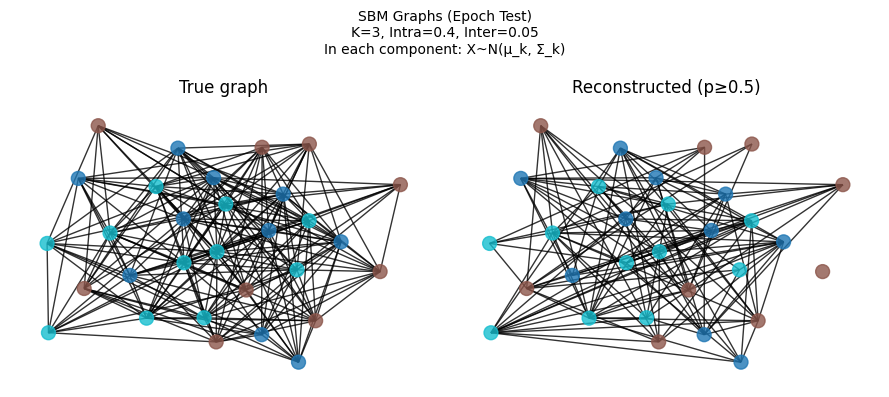

In [69]:
test_model(graph_model, dataset)
torch.save(graph_model.state_dict(), "temporal_graph_vae_sbm.pt")

# Question 2: Conditional Variational Autoencoder (CVAE) for Digit Generation

This note introduces a **Conditional Variational Autoencoder (CVAE)** for image generation on the **MNIST** dataset. The goal is to learn a deep latent-variable model that can synthesize digits conditioned on a desired label—e.g., generate a “2” on demand—and optionally modulate the writing style.


## **Problem setup**

We observe training pairs of handwritten digits and their class labels
$$
\mathcal{D} = {(x^{(i)}, y^{(i)})}_{i=1}^N,
$$
where $x^{(i)} \in \mathbb{R}^{28\times28}$ is an image and $y^{(i)} \in {0,\dots,9}$ is the corresponding digit label.
Our goal is to model the conditional data distribution
$$
p_\theta(x \mid y),
$$
so that, given any label $y$, the model can generate realistic samples $x$ of that digit.



100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 484kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.48MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.55MB/s]


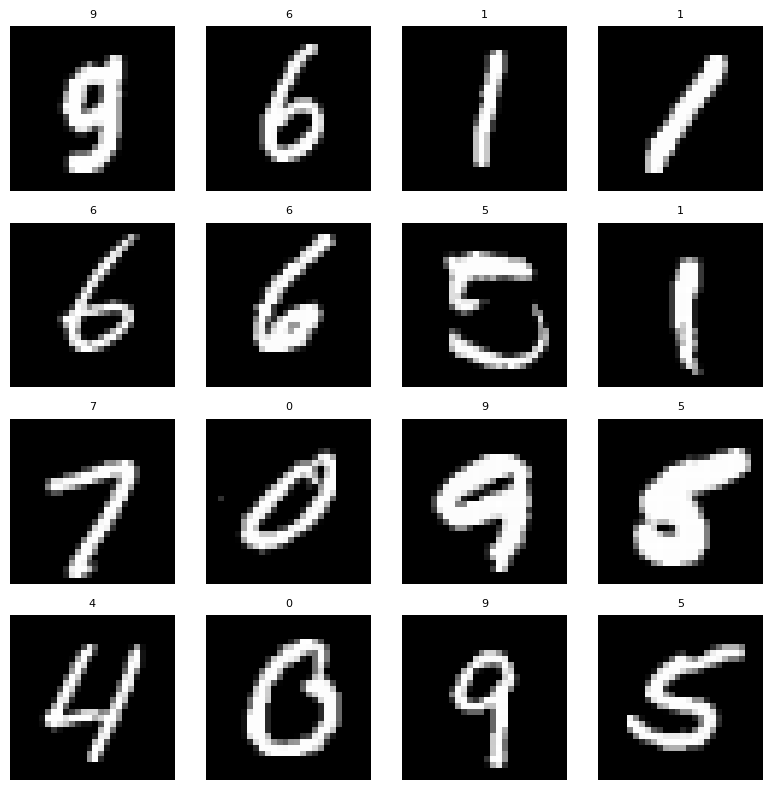

In [12]:
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

# data visualization
def show_grid(images, titles=None, nrows=4, ncols=4, figsize=(8,8)):
    plt.figure(figsize=figsize)
    for i in range(nrows * ncols):
        plt.subplot(nrows, ncols, i + 1)
        img = images[i]
        if isinstance(img, torch.Tensor):
            img = img.squeeze().cpu().numpy()
        plt.imshow(img, cmap='gray')
        plt.axis('off')
        if titles is not None:
            plt.title(titles[i], fontsize=8)
    plt.tight_layout()
    plt.show()

dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
dataloader = DataLoader(dataset, batch_size=16, shuffle=True)
data_iter = iter(dataloader)
images_batch, labels_batch = next(data_iter)
imgs = images_batch[:16]
labs = labels_batch[:16]
show_grid([img for img in imgs], titles=[str(int(l)) for l in labs], nrows=4, ncols=4)

### **Model setup**

We introduce a latent variable $ z \in \mathbb{R}^m $ that captures continuous variations in handwriting style.
The joint distribution is defined as

$$
p_\theta(x, z \mid y) = p_\theta(x \mid z, y) p(z),
$$

where $ p(z) = \mathcal{N}(0, I) $ is a fixed Gaussian prior.

* **Decoder (generative model):** $ p_\theta(x \mid z, y) $ reconstructs the image given latent code $z$ and label $y$.
* **Encoder (inference model):** we approximate the true posterior $ p_\theta(z \mid x, y) $ with

$$
q_\phi(z \mid x, y) = \mathcal{N}\big(\mu_\phi(x, y), \mathrm{diag}(\sigma_\phi^2(x, y))\big).
$$



### **Derivation of the Conditional ELBO**

Our goal is to maximize the conditional log-likelihood of the data:

$$
\log p_\theta(x \mid y).
$$

Since this is intractable, we derive a lower bound (the **conditional ELBO**):

$$
\log p_\theta(x \mid y)
\ge
\mathbb{E}_{q_\phi(z \mid x, y)}[\log p_\theta(x \mid z, y)]

D_{\mathrm{KL}}\big(q_\phi(z \mid x, y) | p(z)\big).
$$

### **Training objective**

The right-hand side is the objective we actually optimize.
We **maximize** the ELBO with respect to parameters $\theta$ and $\phi$, or equivalently, **minimize** the negative ELBO (which is used as the loss in code):

$$
\mathcal{L}_{\text{CVAE}}(x, y)
= -\mathbb{E}_{q_\phi(z \mid x, y)}[\log p_\theta(x \mid z, y)]
+ D_{\mathrm{KL}}\big(q_\phi(z \mid x, y) | p(z)\big).
$$

- The first term (reconstruction loss) ensures that decoded samples resemble the input image.
- The second term (KL divergence) regularizes the latent distribution so that it stays close to the Gaussian prior, which keeps sampling stable during generation.




In [13]:
class Encoder(nn.Module):
    """
    Encoder q_phi(z | x, y).
    """
    def __init__(self, y_dim: int, z_dim: int, hidden_dim: int = 400):
        super().__init__()
        self.y_dim = y_dim
        self.z_dim = z_dim
        self.x_dim = 28 * 28  # MNIST image size

        self.fc1 = nn.Linear(self.x_dim + y_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, z_dim)
        self.fc_logvar = nn.Linear(hidden_dim, z_dim)

    def forward(self, x: torch.Tensor, y: torch.Tensor):
        B = x.size(0)

        x_flat = x.view(B, -1)

        y_one_hot = F.one_hot(y, num_classes=self.y_dim).float()

        h = torch.cat([x_flat, y_one_hot], dim=-1)
        h = F.relu(self.fc1(h))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar


class Decoder(nn.Module):
    """
    Decoder p_theta(x | z, y).

    Takes latent code z and label y, and outputs logits for Bernoulli
    pixels:
        p_theta(x | z, y) = Bernoulli(sigmoid(logits)) (per pixel).
    """
    def __init__(self, y_dim: int, z_dim: int, hidden_dim: int = 400):
        super().__init__()
        self.y_dim = y_dim
        self.z_dim = z_dim
        self.x_dim = 28 * 28
        self.fc1 = nn.Linear(z_dim + y_dim, hidden_dim)
        self.fc_out = nn.Linear(hidden_dim, self.x_dim)

    def forward(self, z: torch.Tensor, y: torch.Tensor):
        B = z.size(0)

        # One-hot encode labels: [B, y_dim]
        y_one_hot = F.one_hot(y, num_classes=self.y_dim).float()

        h = torch.cat([z, y_one_hot], dim=-1)

        h = F.relu(self.fc1(h))

        x_logits_flat = self.fc_out(h)

        x_logits = x_logits_flat.view(B, 1, 28, 28)

        return x_logits


class CVAE(nn.Module):
    """
    Conditional Variational Autoencoder for MNIST.

    Model:
        p(z) = N(0, I)
        p_theta(x | z, y) = decoder(z, y)
        q_phi(z | x, y) = encoder(x, y)

    This module wires:
      - Encoder: q_phi(z | x, y)
      - Decoder: p_theta(x | z, y)
      - Reparameterization trick: z = mu + eps * std
      - Forward pass: returns reconstruction logits, mu, logvar
    """
    def __init__(self, y_dim: int = 10, z_dim: int = 16, hidden_dim: int = 400):
        super().__init__()
        self.y_dim = y_dim
        self.z_dim = z_dim

        self.encoder = Encoder(y_dim=y_dim, z_dim=z_dim, hidden_dim=hidden_dim)
        self.decoder = Decoder(y_dim=y_dim, z_dim=z_dim, hidden_dim=hidden_dim)

    def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + eps * std                 # [B, z_dim]
        return z

    def forward(self, x: torch.Tensor, y: torch.Tensor):
        # Encode image and label to approximate posterior parameters
        mu, logvar = self.encoder(x, y)     # [B, z_dim], [B, z_dim]

        # Sample latent z using the reparameterization trick
        z = self.reparameterize(mu, logvar)

        x_logits = self.decoder(z, y)       # [B, 1, 28, 28]

        return x_logits, mu, logvar


In [14]:
def loss_function(x_recon, x, mu, logvar):

    recon_loss = F.binary_cross_entropy_with_logits(
        x_recon, x, reduction="sum"
    )
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    total_loss = recon_loss + kl_loss
    return total_loss, recon_loss, kl_loss


In [15]:
# training
# dataloader
batch_size = 128

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),  # maps images to [0,1] tensors
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CVAE(y_dim=10, z_dim=20, hidden_dim=400).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 40
### don't edit this !!!
for epoch in range(1, epochs+1):
    model.train()
    total_loss = 0.0
    total_recon = 0.0
    total_kl = 0.0
    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        x_recon, mu, logvar = model(x, y)

        loss, recon_loss, kl_loss = loss_function(x_recon, x, mu, logvar)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    n = len(train_loader.dataset)
    print(f"Epoch {epoch:02d}  Loss per example: {total_loss / n:.4f}  Recon: {total_recon / n:.4f}  KL: {total_kl / n:.4f}")


Epoch 01  Loss per example: 163.0712  Recon: 148.7224  KL: 14.3488
Epoch 02  Loss per example: 119.9571  Recon: 99.7927  KL: 20.1644
Epoch 03  Loss per example: 112.6005  Recon: 90.9961  KL: 21.6044
Epoch 04  Loss per example: 109.1339  Recon: 87.0822  KL: 22.0517
Epoch 05  Loss per example: 107.0656  Recon: 84.9273  KL: 22.1383
Epoch 06  Loss per example: 105.6779  Recon: 83.4914  KL: 22.1865
Epoch 07  Loss per example: 104.6005  Recon: 82.4392  KL: 22.1612
Epoch 08  Loss per example: 103.8032  Recon: 81.6754  KL: 22.1278
Epoch 09  Loss per example: 103.0990  Recon: 81.0444  KL: 22.0546
Epoch 10  Loss per example: 102.5558  Recon: 80.5130  KL: 22.0428
Epoch 11  Loss per example: 102.0901  Recon: 80.0851  KL: 22.0050
Epoch 12  Loss per example: 101.6793  Recon: 79.7368  KL: 21.9425
Epoch 13  Loss per example: 101.2766  Recon: 79.3739  KL: 21.9027
Epoch 14  Loss per example: 100.9821  Recon: 79.1125  KL: 21.8695
Epoch 15  Loss per example: 100.7201  Recon: 78.8436  KL: 21.8765
Epoch 16 

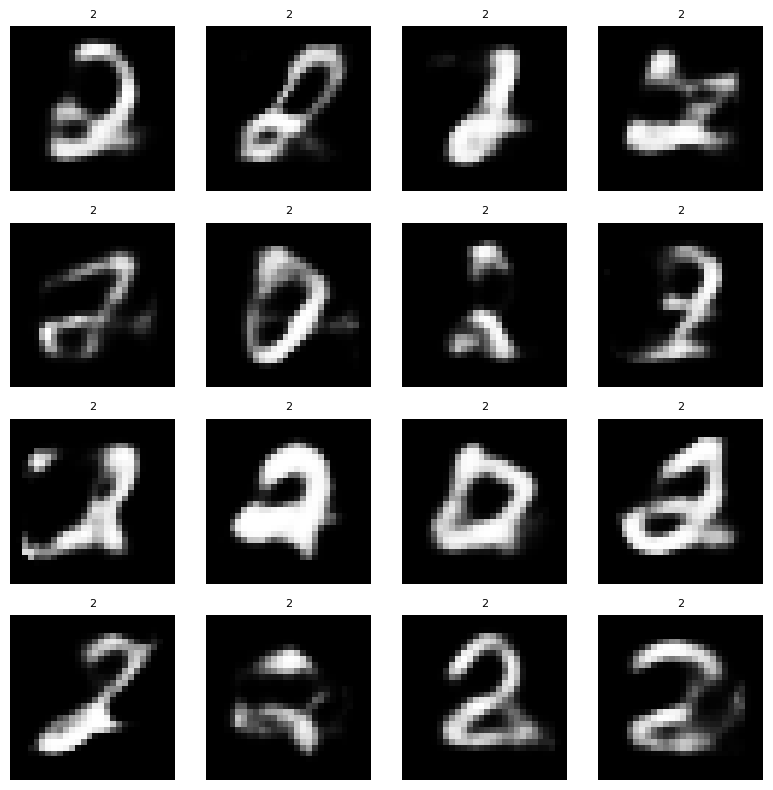

In [16]:
# model inferencing
model.eval()
with torch.no_grad():
    # choose the digit you want to generate
    digit = 2   # for example, "2"
    n = 16      # number of samples to generate

    # labels: a batch of size n, all equal to `digit`
    y = torch.full((n,), digit, dtype=torch.long, device=device)

    # match the latent size to your model automatically
    z_dim = model.z_dim
    z = torch.randn(n, z_dim, device=device)

    # decode to images (logits)
    x_logits = model.decoder(z, y)
    x_gen = torch.sigmoid(x_logits).cpu()

# visualize generated digits
show_grid(
    [x_gen[i] for i in range(n)],
    titles=[str(digit)] * n,
    nrows=4,
    ncols=4,
)


### Student ID Generation
After training your CVAE model, define a function that takes your 9-digit student ID as input and generates one digit per number in your ID. Each digit must be conditioned on its corresponding label (0–9). Arrange the generated digits horizontally in a 1×9 grid to visually display your complete student ID as a sequence of generated MNIST-style digits. Include this final generated image in your report.

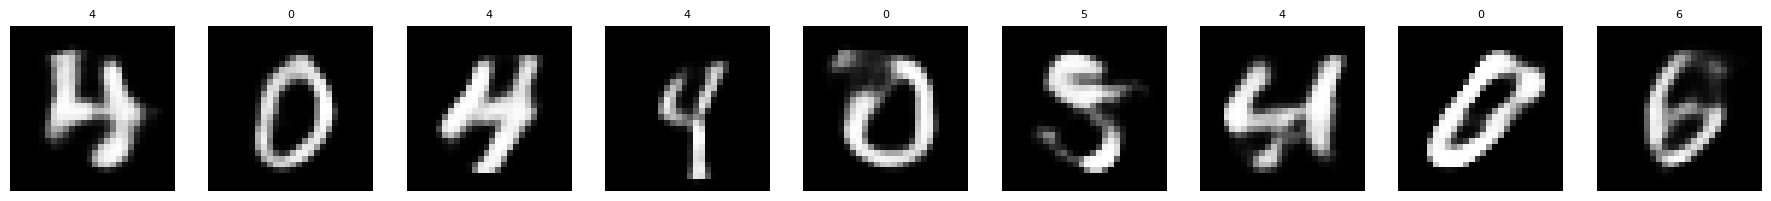

tensor([[[[3.0464e-07, 2.2800e-07, 3.6987e-07,  ..., 3.2041e-07,
           3.4279e-07, 2.2931e-07],
          [3.1076e-07, 3.0678e-07, 2.0682e-07,  ..., 4.2088e-07,
           1.9105e-07, 2.8564e-07],
          [1.7501e-07, 4.0548e-07, 2.4658e-08,  ..., 4.7486e-14,
           2.5144e-07, 2.9542e-07],
          ...,
          [2.7478e-07, 1.9503e-07, 4.2392e-12,  ..., 6.6202e-08,
           1.7853e-09, 2.8512e-07],
          [3.3748e-07, 3.4469e-07, 3.1377e-07,  ..., 5.8202e-14,
           4.1368e-07, 2.5281e-07],
          [4.0933e-07, 2.4404e-07, 3.3748e-07,  ..., 2.3926e-07,
           2.5373e-07, 3.0175e-07]]],


        [[[1.6099e-08, 1.1916e-08, 1.7594e-08,  ..., 2.3036e-08,
           1.7948e-08, 1.4979e-08],
          [1.1918e-08, 1.8568e-08, 1.7237e-08,  ..., 2.6177e-08,
           1.0587e-08, 1.6212e-08],
          [2.7530e-08, 1.5212e-08, 2.4950e-11,  ..., 1.2215e-17,
           1.4228e-08, 1.6500e-08],
          ...,
          [1.8071e-08, 2.0417e-08, 2.8760e-12,  ..., 4.03

In [17]:
def generate_student_digits(model, student_id, device='cpu'):
    if not isinstance(device, torch.device):
        device = torch.device(device)

    model.eval()
    with torch.no_grad():
        id_str = str(student_id)
        digits = [int(ch) for ch in id_str]


        n = len(digits)

        y = torch.tensor(digits, dtype=torch.long, device=device)

        z_dim = model.z_dim
        z = torch.randn(n, z_dim, device=device)
        x_logits = model.decoder(z, y)
        x_gen = torch.sigmoid(x_logits).cpu()
        show_grid(
            [x_gen[i] for i in range(n)],
            titles=[str(d) for d in digits],
            nrows=1,
            ncols=n,
            figsize=(2 * n, 2),
        )

    return x_gen

generate_student_digits(model, 404405406, device)

### **Latent Space Exploration**
To demonstrate that your CVAE has learned a meaningful latent representation, write a function that visualizes the latent space of the model.
Select **two random latent directions** in $z$-space, fix a target digit label $y$, and generate a **9×9 grid** of samples by varying these two directions from negative to positive values.
The center of the grid should correspond to $z = 0$ (the mean latent vector), while moving along the axes explores different variations of handwriting style.
After visualizing, **describe what each direction appears to represent**—for example, changes in stroke thickness, slant, or digit shape—and discuss whether the transformations look smooth and interpretable.


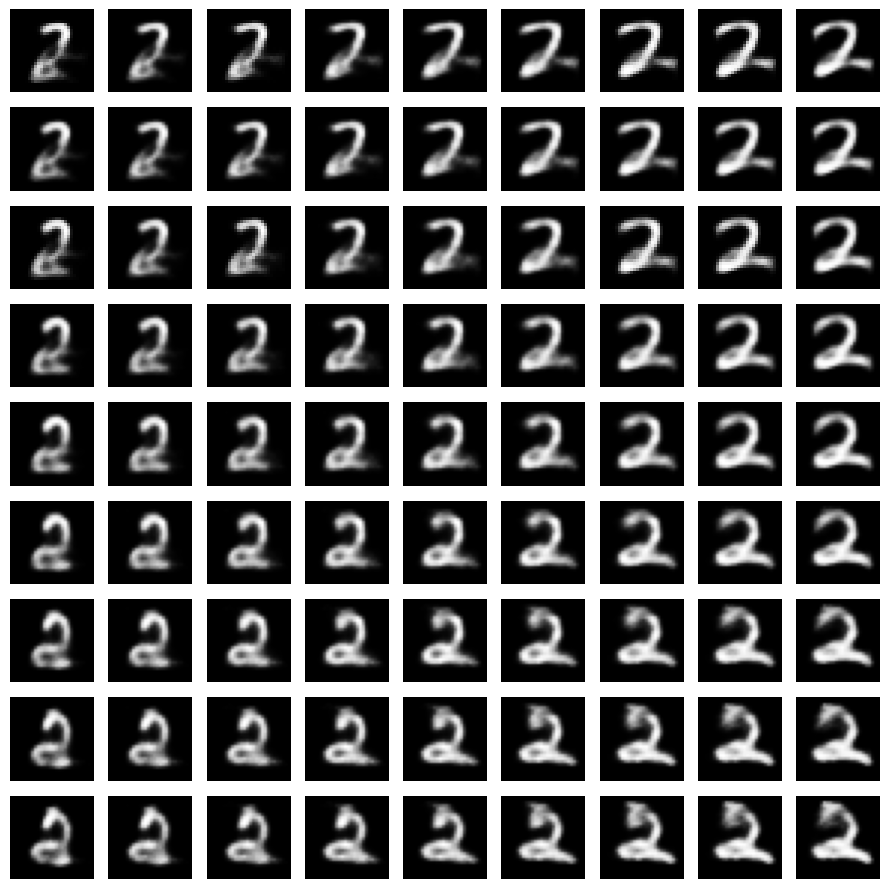

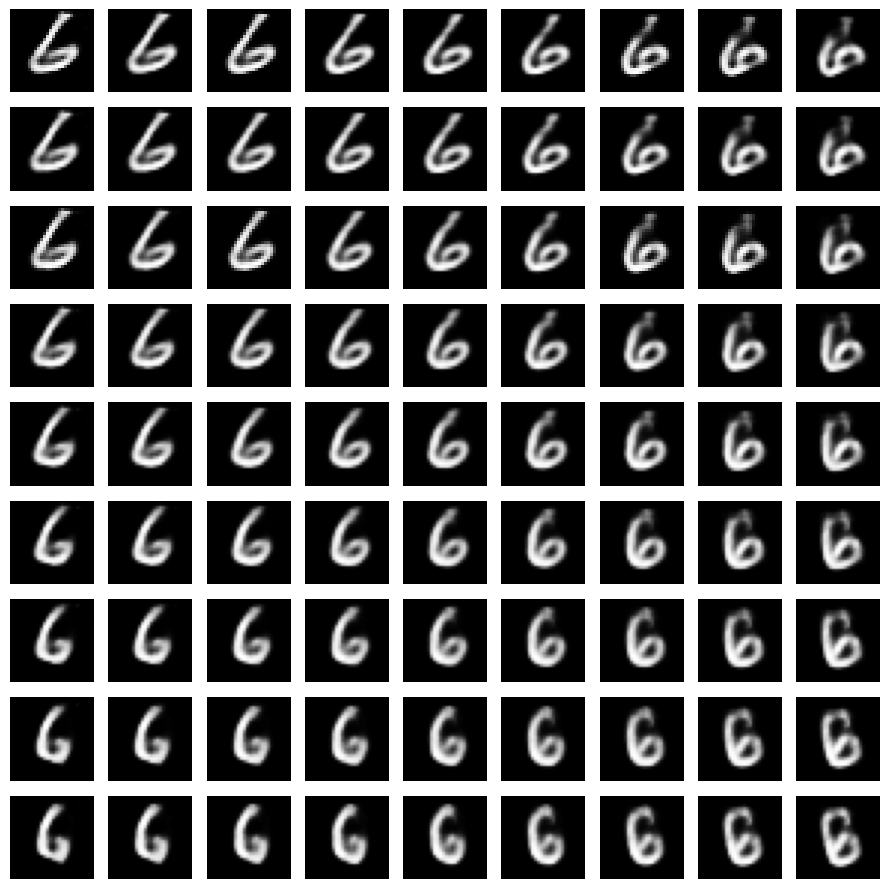

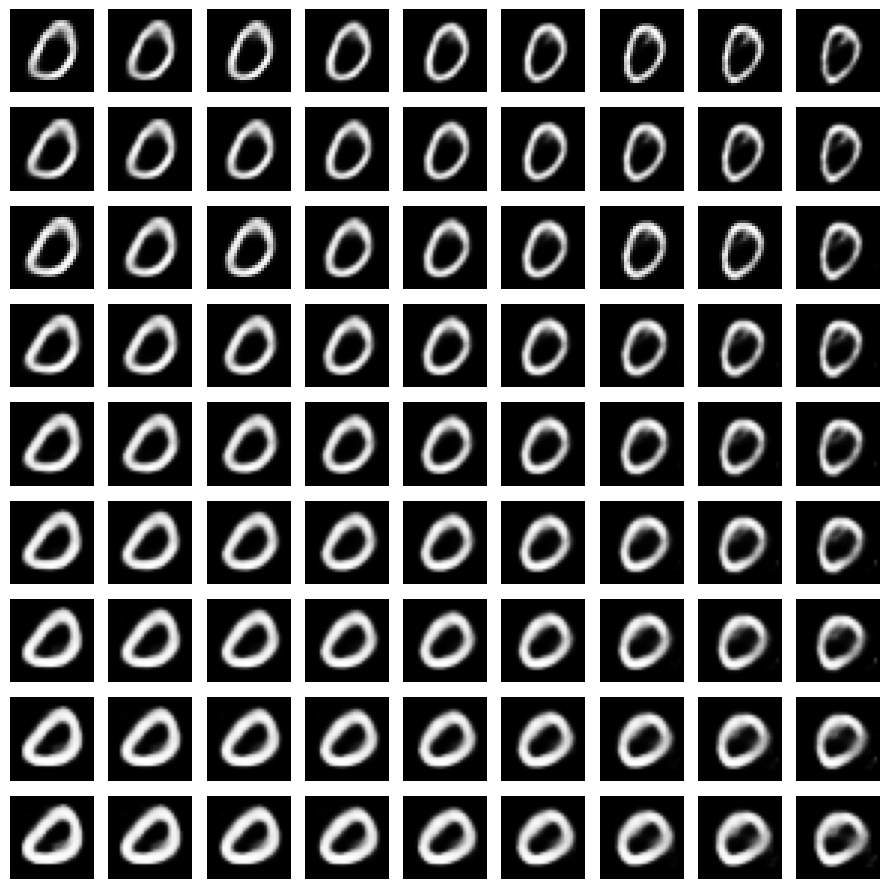

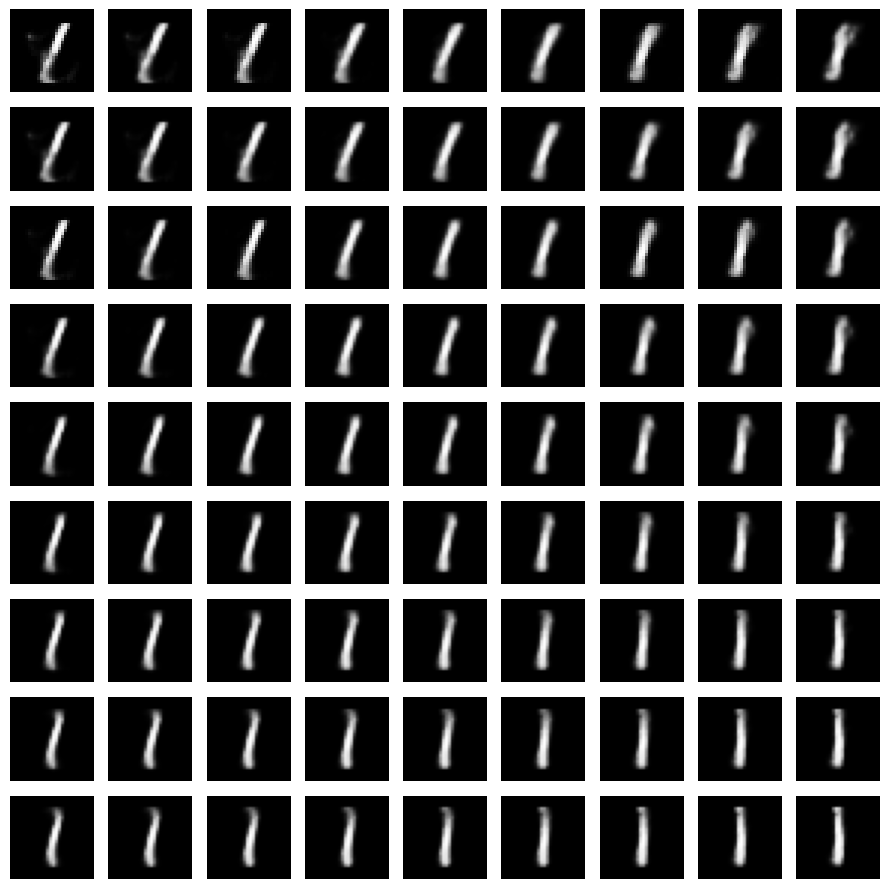

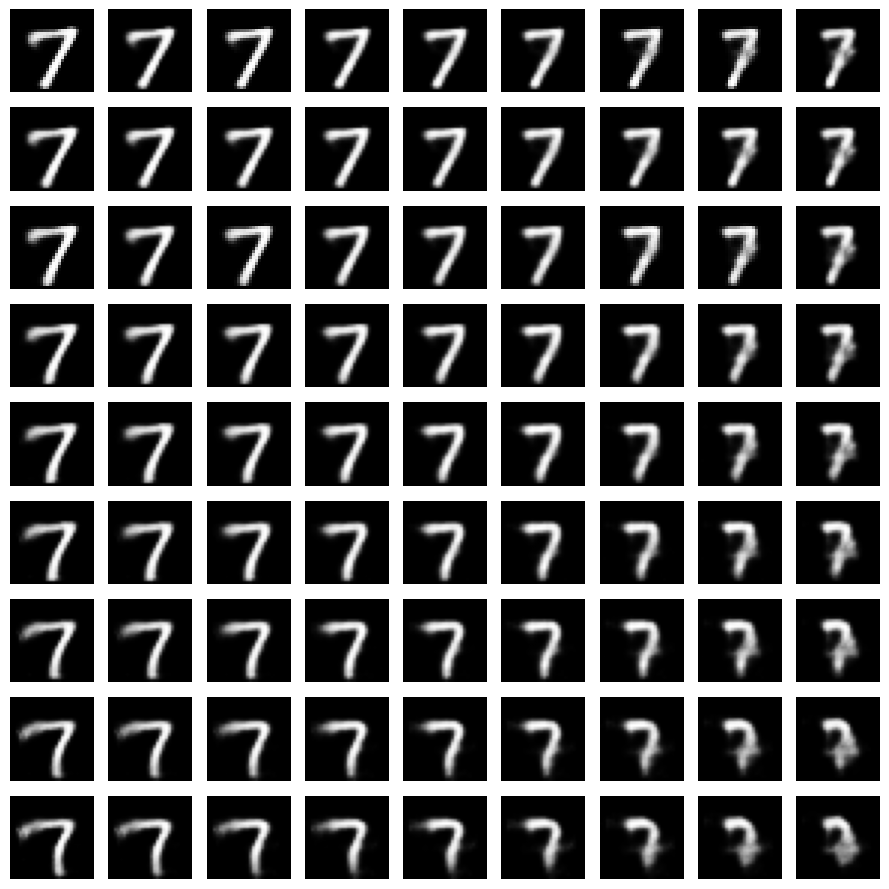

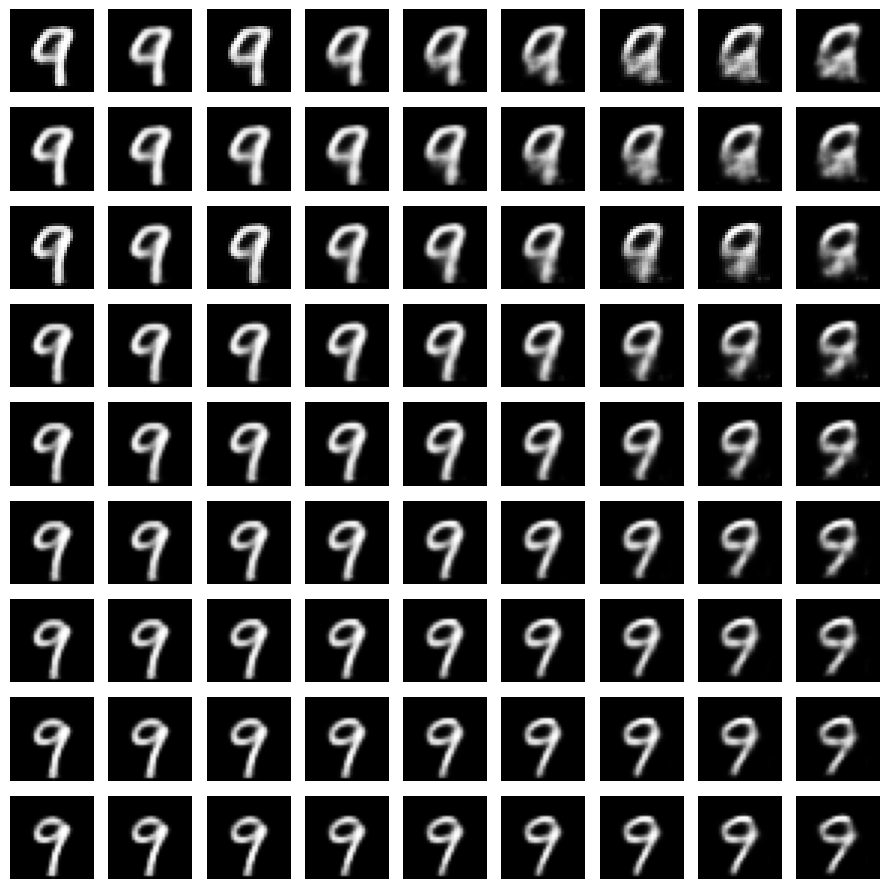

tensor([[[[4.3774e-09, 4.8843e-09, 2.9540e-09,  ..., 4.8392e-09,
           5.2152e-09, 3.9890e-09],
          [3.2769e-09, 5.1416e-09, 6.9854e-09,  ..., 4.7426e-09,
           5.7742e-09, 5.2949e-09],
          [6.4577e-09, 3.5704e-09, 4.3482e-09,  ..., 1.2188e-12,
           3.0731e-09, 3.6278e-09],
          ...,
          [7.6859e-09, 4.3335e-09, 8.6774e-07,  ..., 2.1482e-08,
           2.0592e-09, 5.0555e-09],
          [4.0521e-09, 3.9639e-09, 6.5083e-09,  ..., 9.4256e-13,
           6.0315e-09, 6.0507e-09],
          [6.1605e-09, 3.8645e-09, 6.8644e-09,  ..., 3.3118e-09,
           5.3888e-09, 3.0127e-09]]],


        [[[1.6717e-08, 1.9478e-08, 1.1504e-08,  ..., 1.8084e-08,
           1.9300e-08, 1.5776e-08],
          [1.2177e-08, 2.0256e-08, 2.6488e-08,  ..., 1.8698e-08,
           2.2016e-08, 1.9677e-08],
          [2.4652e-08, 1.4174e-08, 1.7417e-08,  ..., 9.1523e-12,
           1.2187e-08, 1.4311e-08],
          ...,
          [2.7937e-08, 1.6270e-08, 2.9244e-06,  ..., 7.55

In [19]:
import numpy as np

def visualize_latent_space(model, y_label, z_dim=None, grid_size=9, scale=2.5, device='cpu'):
    if not isinstance(device, torch.device):
        device = torch.device(device)

    if z_dim is None:
        z_dim = model.z_dim

    model.eval()
    with torch.no_grad():
        d1 = torch.randn(z_dim, device=device)
        d2 = torch.randn(z_dim, device=device)
        d1 = d1 / d1.norm()
        d2 = d2 / d2.norm()

        lin = torch.linspace(-scale, scale, steps=grid_size, device=device)

        zs = []
        labels = []
        for i in range(grid_size):
            for j in range(grid_size):
                a = lin[i]
                b = lin[j]
                z_ij = a * d1 + b * d2
                zs.append(z_ij)
                labels.append(y_label)

        zs = torch.stack(zs, dim=0)
        y = torch.tensor(labels, dtype=torch.long, device=device)

        x_logits = model.decoder(zs, y)
        x_gen = torch.sigmoid(x_logits).cpu()

        show_grid(
            [x_gen[k] for k in range(len(x_gen))],
            titles=None,
            nrows=grid_size,
            ncols=grid_size,
            figsize=(grid_size, grid_size),
        )

    return x_gen

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# same digit, different random directions
visualize_latent_space(model, y_label=2, device=device)
visualize_latent_space(model, y_label=6, device=device)

# different digits
visualize_latent_space(model, y_label=0, device=device)
visualize_latent_space(model, y_label=1, device=device)
visualize_latent_space(model, y_label=7, device=device)
visualize_latent_space(model, y_label=9, device=device)




### **Bonus – Style-Controlled Student ID Generation**
Extend your CVAE to allow **style control** along a latent dimension.
Write a function that takes your **9-digit student ID** as input and generates one digit per number, arranged in a single row.
Additionally, for each digit, gradually vary the “style” dimension from thin to thick (or light to bold) as you move across the row, so that the same digit shows different styles.
Include the resulting image in your report and briefly describe how the style changes are reflected in the generated digits.


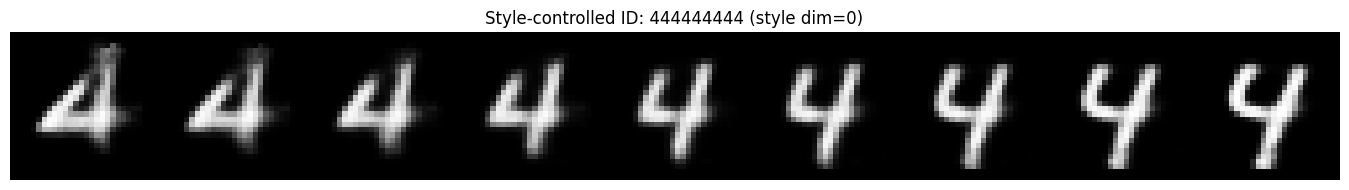

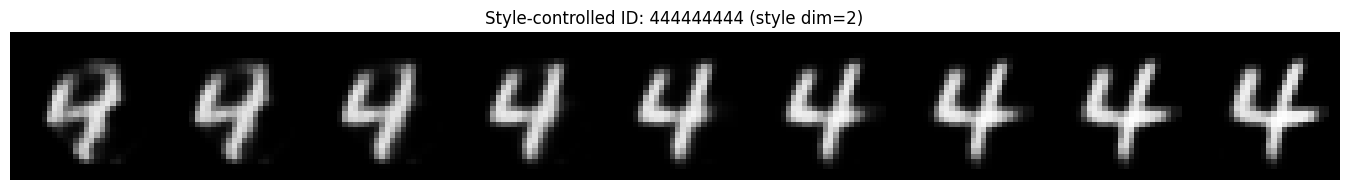

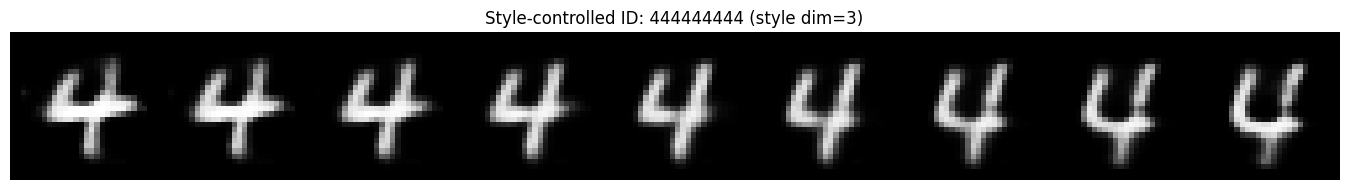

tensor([[[8.7559e-08, 5.7140e-08, 7.6444e-08,  ..., 4.2621e-08,
          3.9821e-08, 4.8113e-08],
         [1.4234e-07, 9.9542e-08, 1.1708e-07,  ..., 4.1195e-08,
          3.5548e-08, 4.9020e-08],
         [5.8989e-08, 9.0949e-08, 6.7950e-09,  ..., 8.9301e-12,
          2.9981e-08, 3.3021e-08],
         ...,
         [1.1158e-07, 6.3357e-08, 2.0545e-13,  ..., 3.9203e-10,
          6.0011e-09, 6.6050e-08],
         [8.1677e-08, 8.5643e-08, 9.7019e-08,  ..., 3.5964e-11,
          5.7146e-08, 4.1451e-08],
         [1.0933e-07, 5.7853e-08, 8.8380e-08,  ..., 3.6960e-08,
          5.6653e-08, 2.9746e-08]]])

In [46]:
def generate_style_controlled_id(model, student_id, style_dim=0, scale=3.0, device='cpu'):
    if not isinstance(device, torch.device):
        device = torch.device(device)

    model.eval()
    with torch.no_grad():
        id_str = str(student_id)
        digits = [int(ch) for ch in id_str]
        n = len(digits)

        # Labels tensor
        y = torch.tensor(digits, dtype=torch.long, device=device)  # [n]

        # Latent dimension
        z_dim = model.z_dim
        assert 0 <= style_dim < z_dim, "style_dim must be in [0, z_dim-1]"

        z = torch.zeros(n, z_dim, device=device)

        style_values = torch.linspace(-scale, scale, steps=n, device=device)

        z[:, style_dim] = style_values
        # Decode
        x_logits = model.decoder(z, y)
        x_gen = torch.sigmoid(x_logits).cpu()


        stitched_img = torch.zeros(1, 28, 28 * n)
        for i in range(n):
            digit_img = x_gen[i]
            start = i * 28
            end = (i + 1) * 28
            stitched_img[:, :, start:end] = digit_img

        # Visualize
        plt.figure(figsize=(2 * n, 2))
        plt.imshow(stitched_img.squeeze().numpy(), cmap='gray')
        plt.axis('off')
        plt.title(f"Style-controlled ID: {student_id} (style dim={style_dim})")
        plt.tight_layout()
        plt.show()

    return stitched_img

generate_style_controlled_id(model, 444444444, style_dim=0, scale=3.0, device=device)

generate_style_controlled_id(model, 444444444, style_dim=2, scale=5.0, device=device)

generate_style_controlled_id(model, 444444444, style_dim=3, scale=5.0, device=device)


explanation: Varying latent dimension 0 from −3 to +3 produces a smooth change in style: digits on the left are thin and lightly drawn, while those on the right are thicker and bolder. The identity of each digit is preserved, indicating that this dimension mostly controls style rather than class.

In [49]:
#saver and loader
torch.save(model.state_dict(), "mnist_cvae.pt")
print( "Models saved: temporal_graph_vae_sbm.pt, mnist_cvae.pt")

Models saved: temporal_graph_vae_sbm.pt, mnist_cvae.pt


In [70]:
from google.colab import drive
drive.mount('/content/drive')
graph_model_path = "/content/drive/MyDrive/GenerativeModels/hw02_DGM/temporal_graph_vae_sbm.pt"
cvae_model_path  = "/content/drive/MyDrive/GenerativeModels/hw02_DGM/mnist_cvae.pt"
torch.save(graph_model.state_dict(), graph_model_path)
torch.save(model.state_dict(), cvae_model_path)
print("Models saved successfully:")
print(" -", graph_model_path)
print(" -", cvae_model_path)

Mounted at /content/drive
Models saved successfully:
 - /content/drive/MyDrive/GenerativeModels/hw02_DGM/temporal_graph_vae_sbm.pt
 - /content/drive/MyDrive/GenerativeModels/hw02_DGM/mnist_cvae.pt


In [ ]:
graph_model = TemporalGraphVAE(n_nodes=..., feat_dim=..., z_dim=..., hidden_dim=...)
graph_model.load_state_dict(torch.load("temporal_graph_vae_sbm.pt"))
graph_model.eval()

cvae_model = CVAE(y_dim=10, z_dim=20, hidden_dim=400)
cvae_model.load_state_dict(torch.load("mnist_cvae.pt"))
cvae_model.eval()
